<h2 style="color:rgb(0,120,170)">Path length</h2>

**Question:** how good are the paths, i.e. how long are they?

**Setup:** the average path length per batch was counted

The maps are the 7 batches from `maps/maps.ipynb` (10 maps each, 10 × 10, start (0, 0), goal (10, 10)), loaded from `maps/maps_batches.json`. Run `maps/maps.ipynb` first if the file doesn't exist.

| column | batch |
|---|---|
| batch_1 | different amount of obstacles (2–7, convex) |
| batch_2 | convex/concave obstacles |
| batch_3 | no obstacles |
| batch_4 | obstacles make no impact (straight line free) |
| batch_5 | few obstacles (2) |
| batch_6 | many obstacles (7) |
| batch_7 | random placement |

In [1]:
from IPython.display import Markdown, display

from utils.compare_tables_util import (
    build_path_length_comparison_table,
    format_benchmark_table,
    show_benchmark_tables,
)
from utils.path_planning_utils import build_path_length_tables
from utils.plot_utils import (
    plot_algorithm_batch_means,
    plot_batch_examples_PRM,
    plot_batch_examples_RRT_star,
    plot_batch_examples_VG,
)

In [2]:
from utils.maps_generation_utils import END, START, load_batches

obstacle_batches = load_batches("maps/maps_batches.json")
start, end = START, END
print(len(obstacle_batches), "batches,", [len(b) for b in obstacle_batches], "maps")

7 batches, [10, 10, 10, 10, 10, 10, 10] maps


### Settings

In [4]:
N_EXAMPLES = 3
RRT_KWARGS = {"iterations": 2000}
PRM_KWARGS = {"n_samples": 150, "k": 8}

### Example paths
The first maps of every batch. Gray: the graph or tree the planner built. Red: the found path. Green: start. Blue: goal.

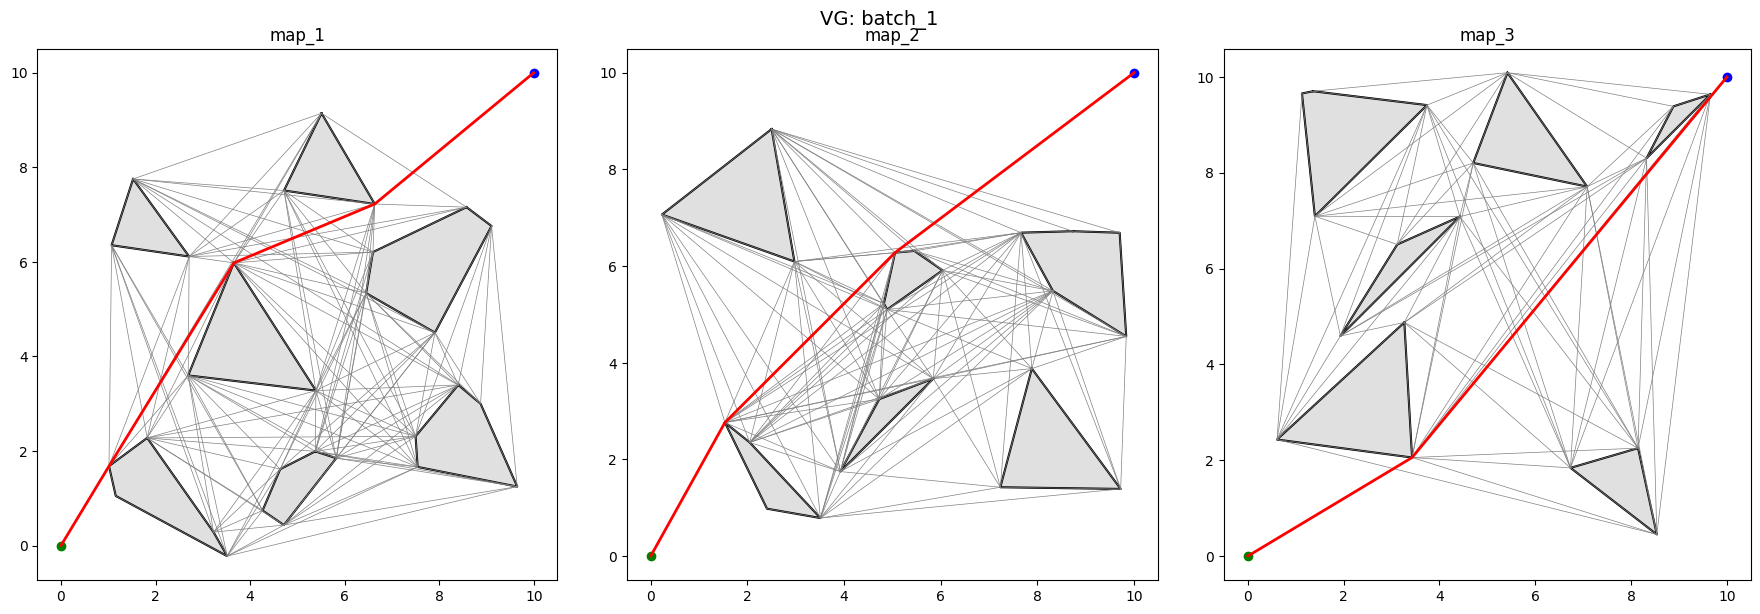

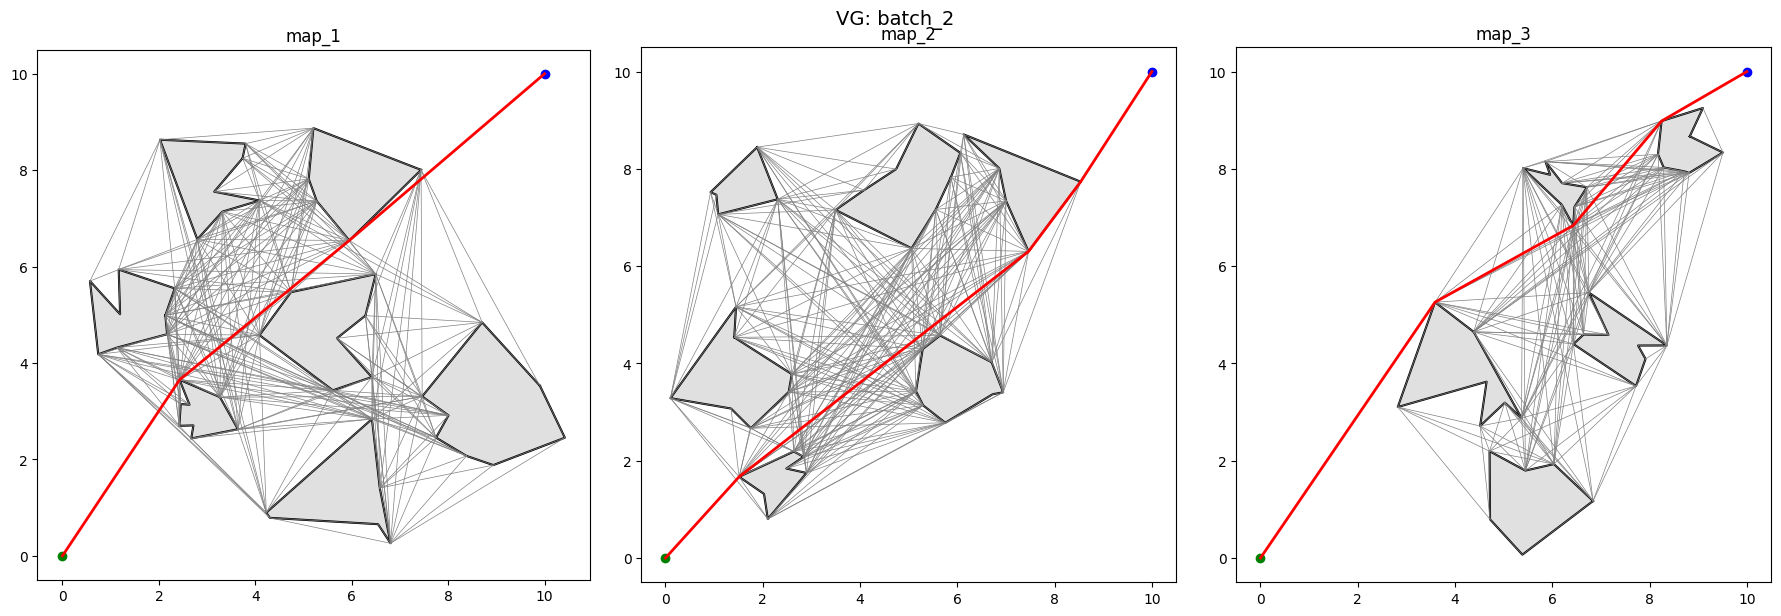

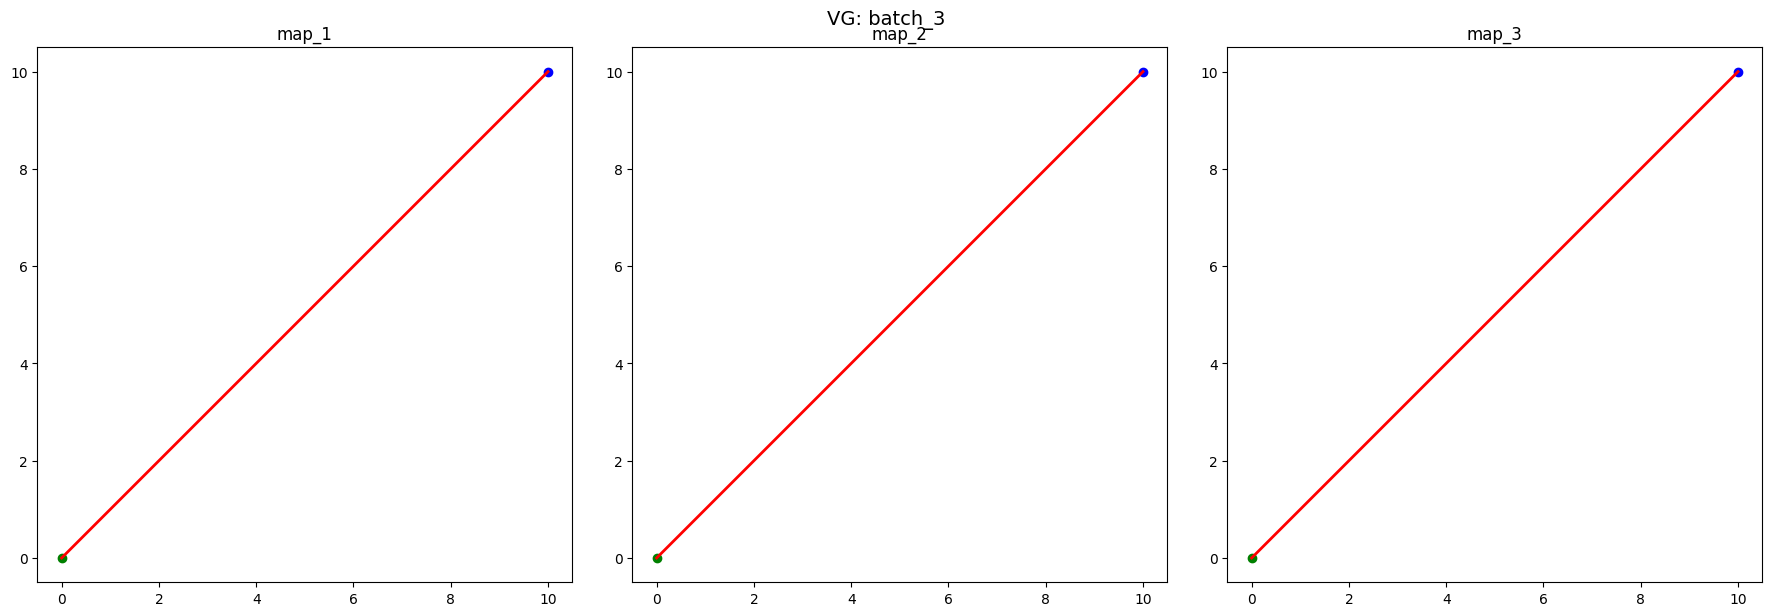

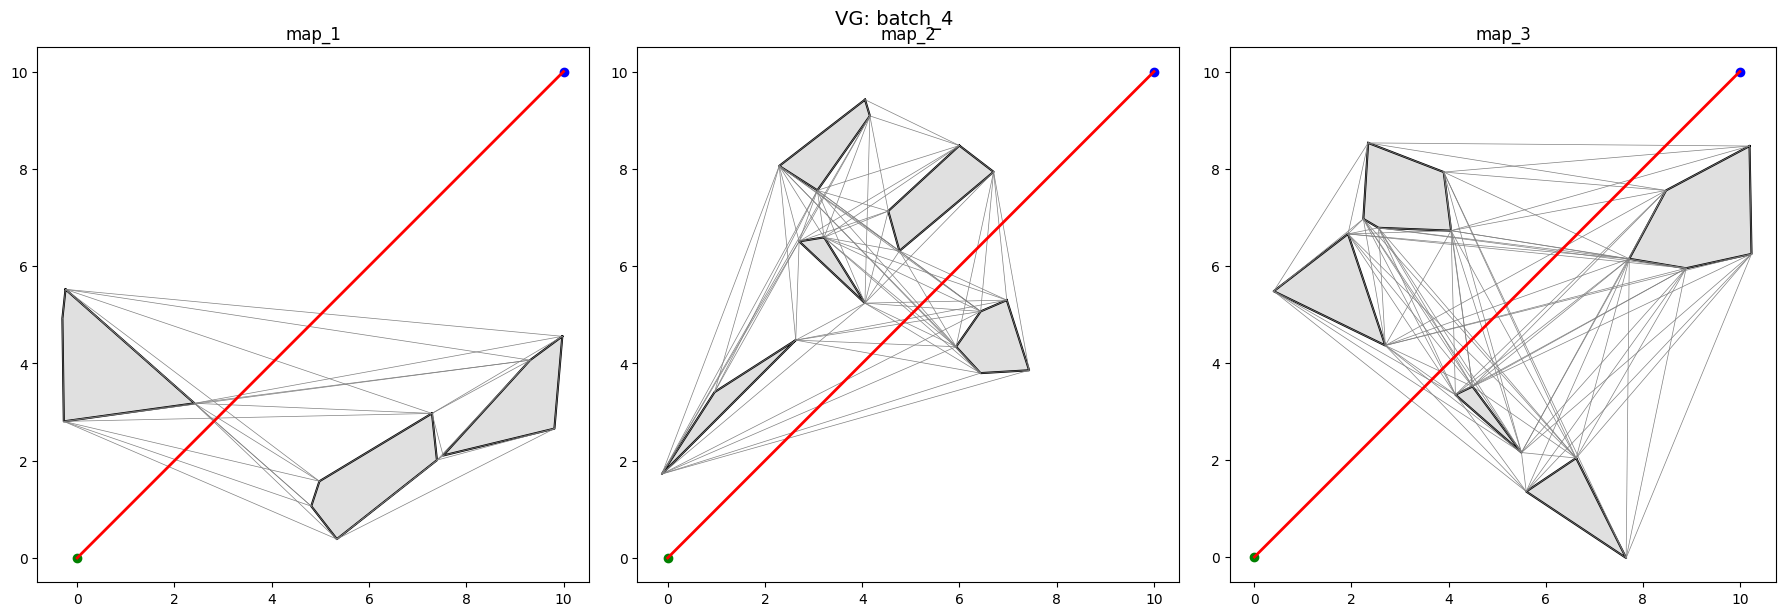

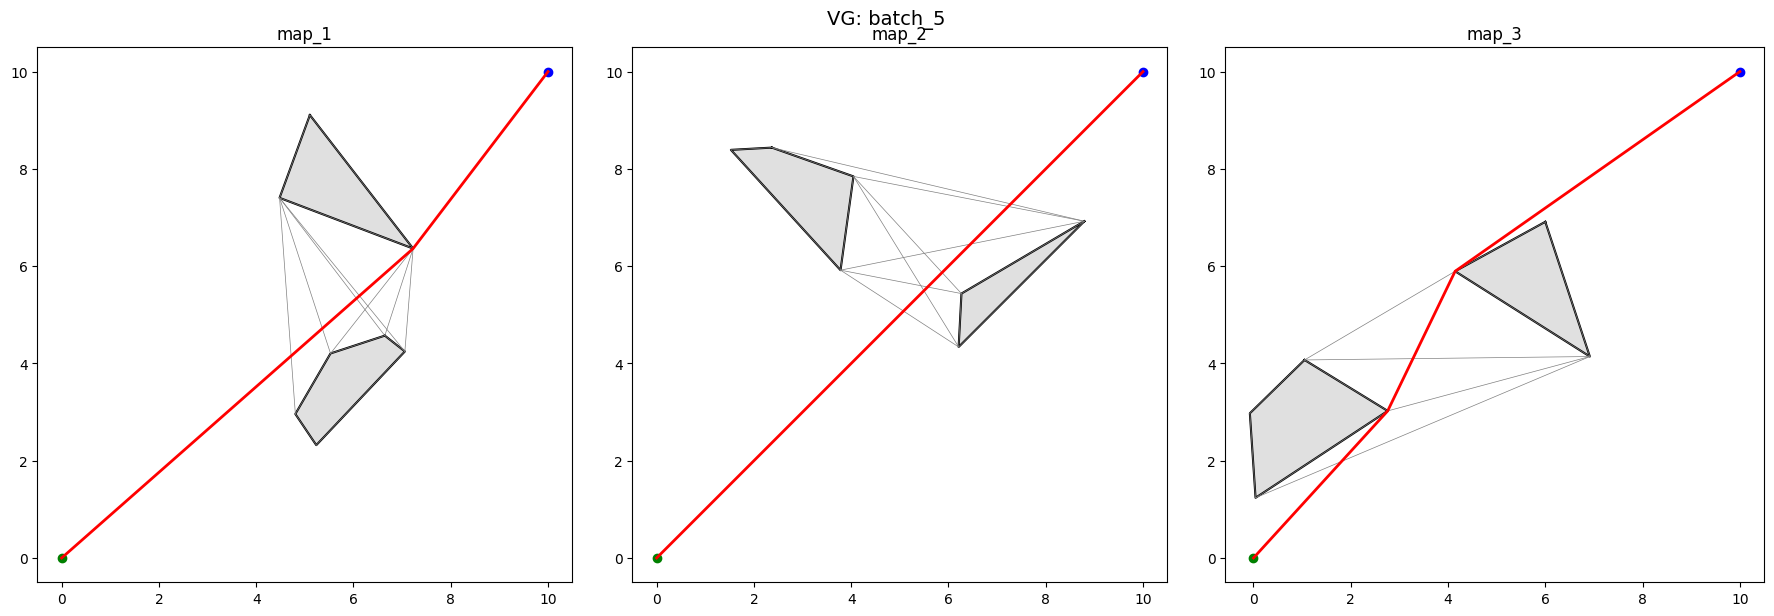

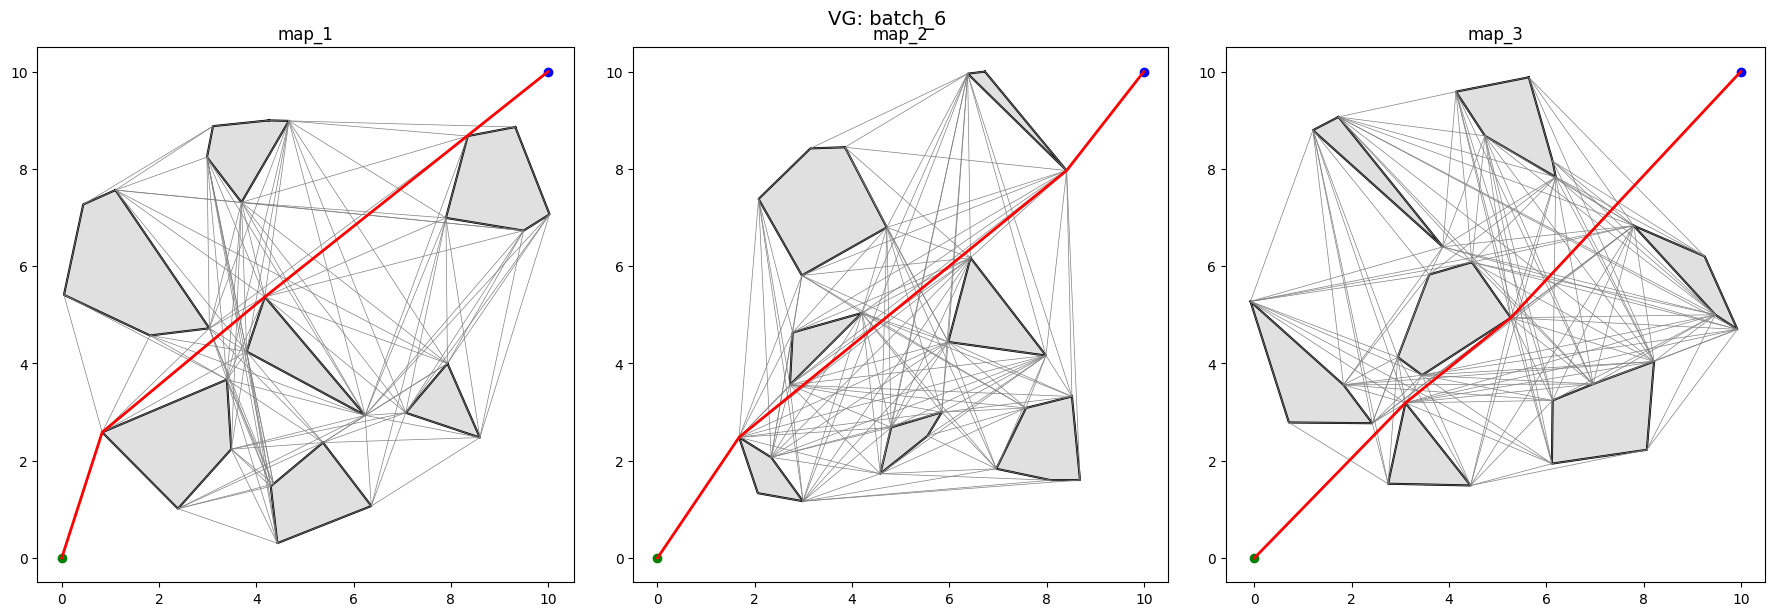

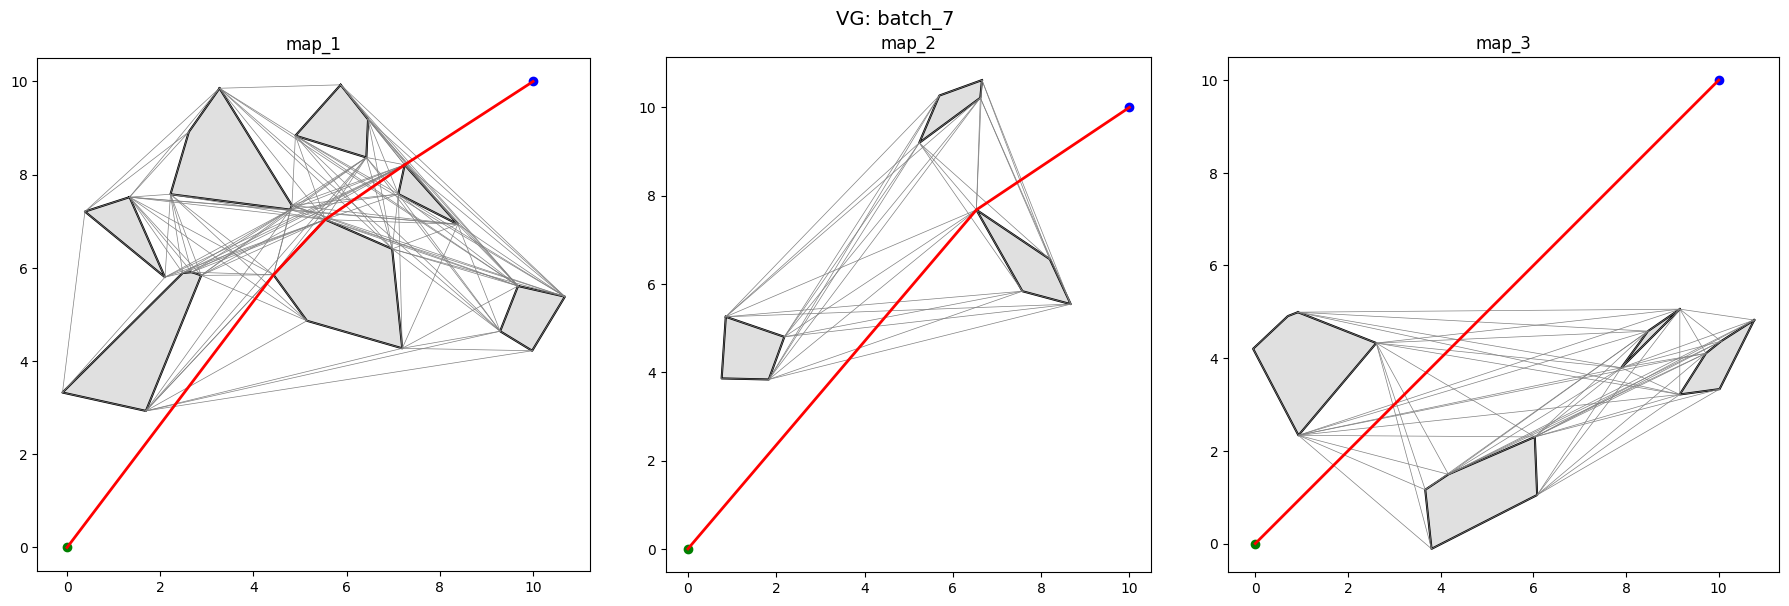

In [5]:
plot_batch_examples_VG(obstacle_batches, start, end, n_examples=N_EXAMPLES);

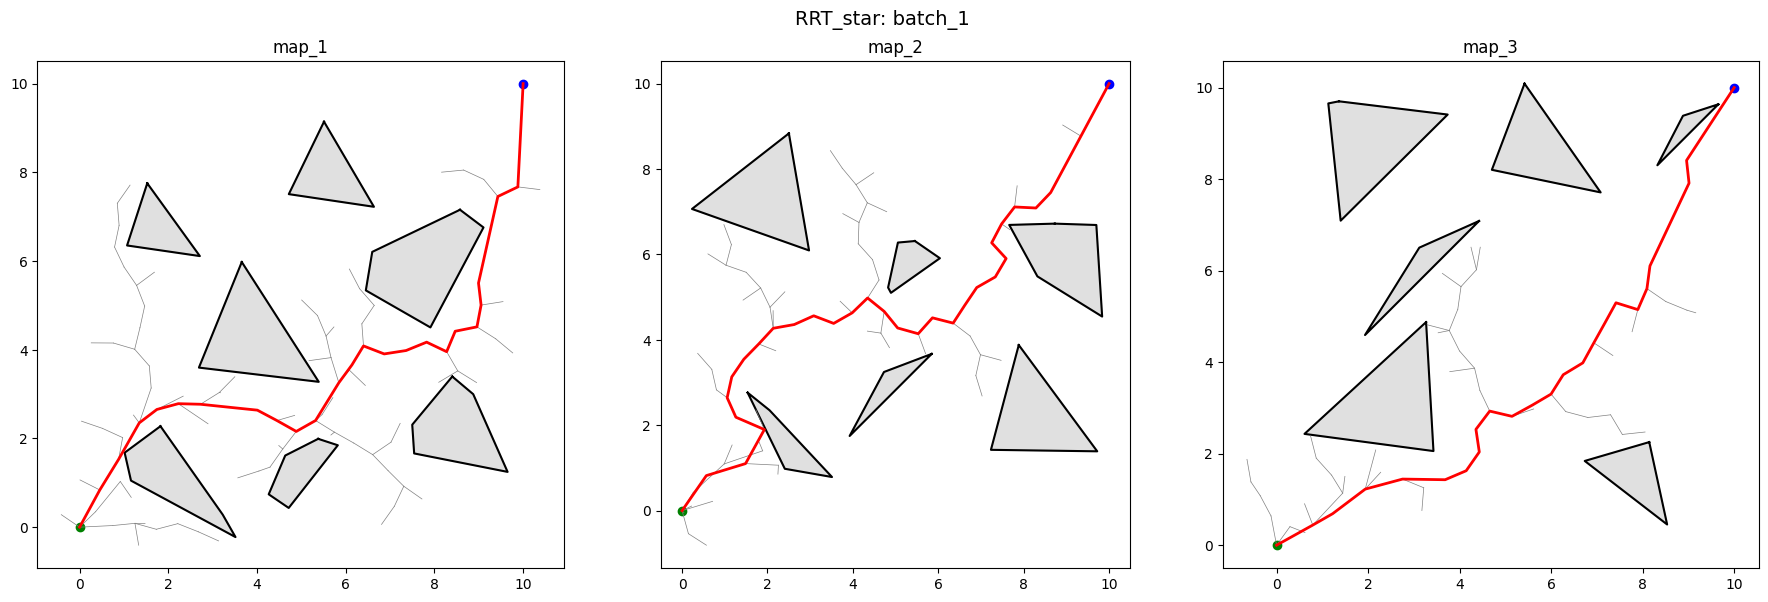

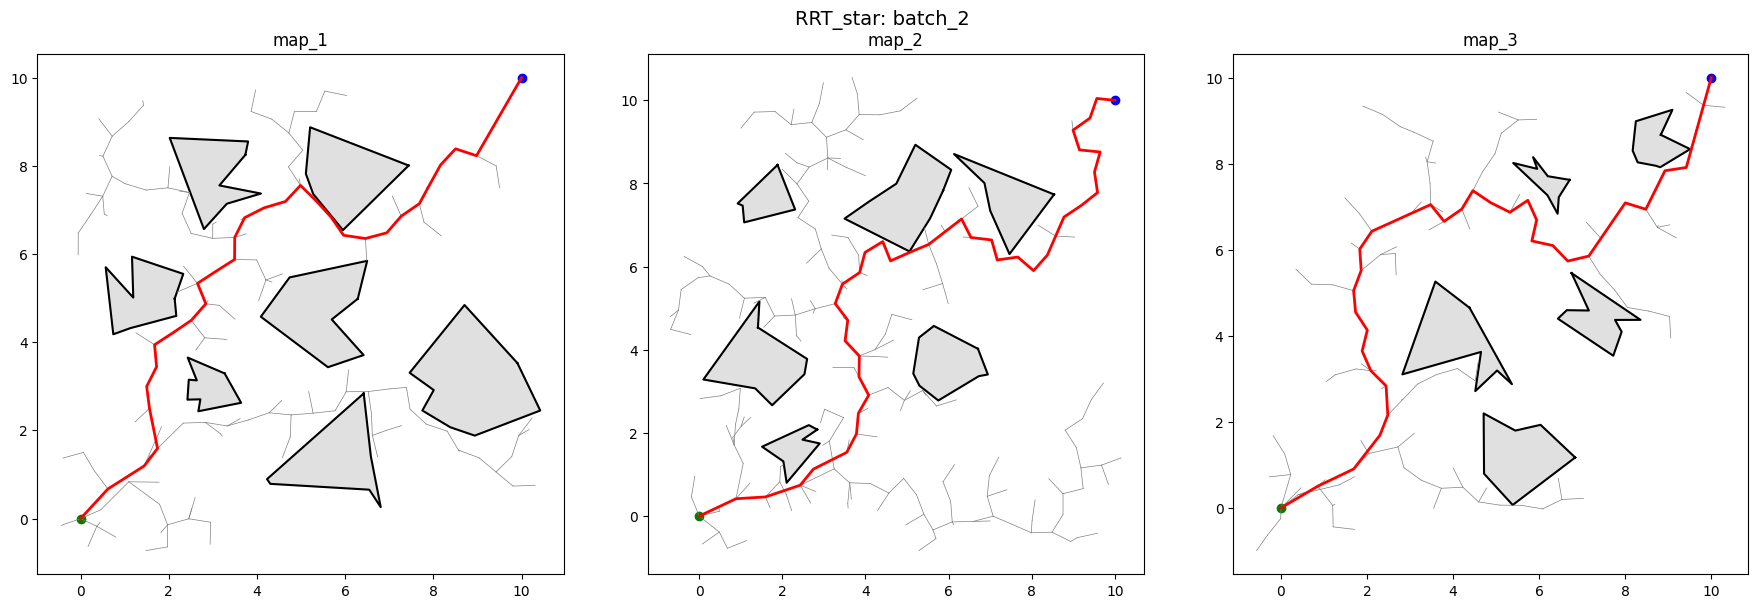

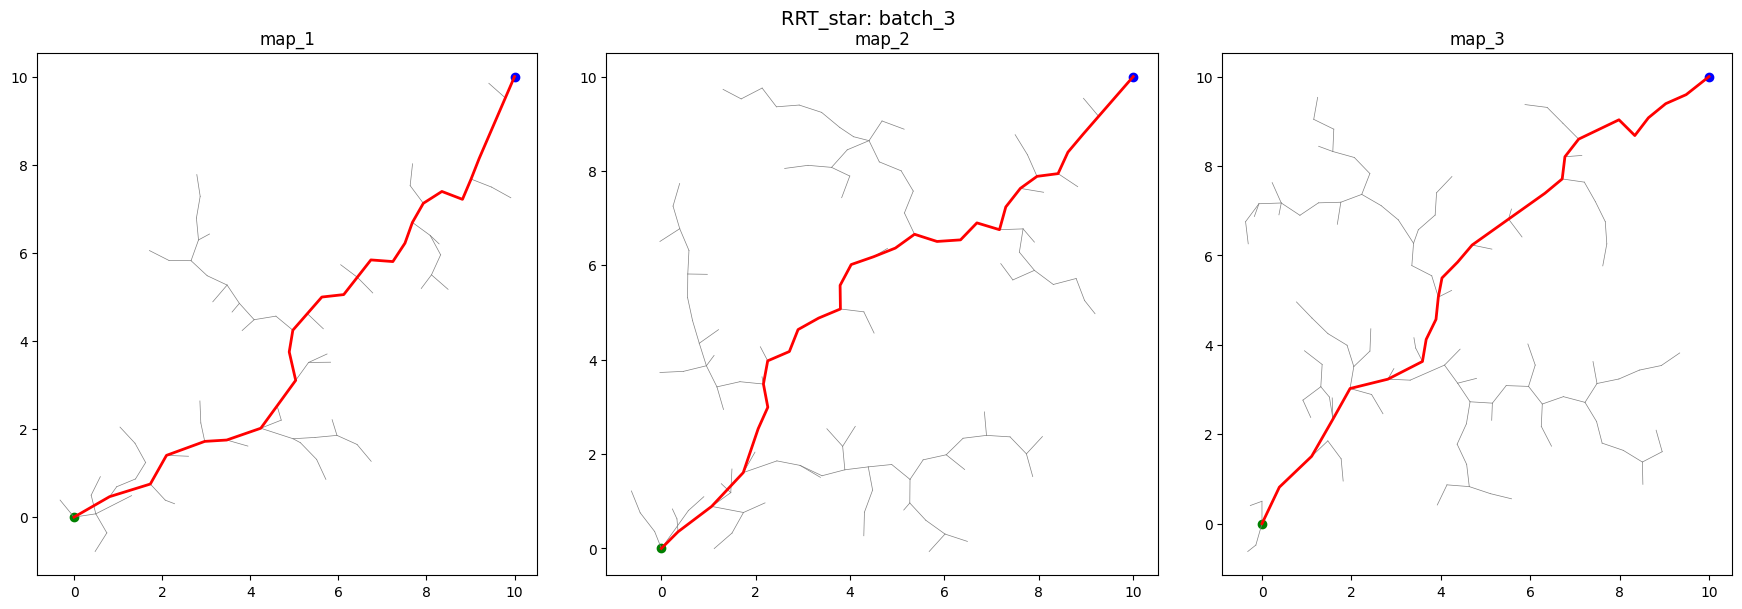

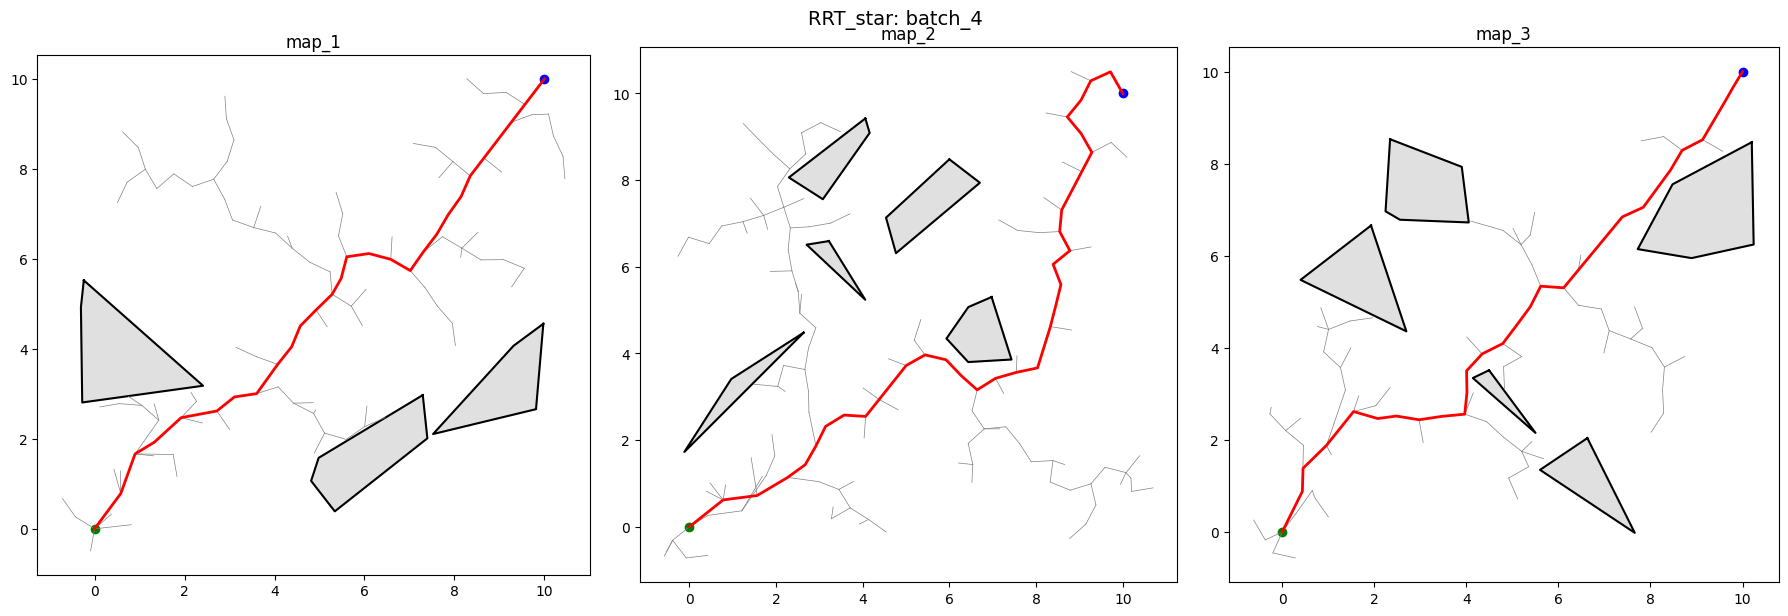

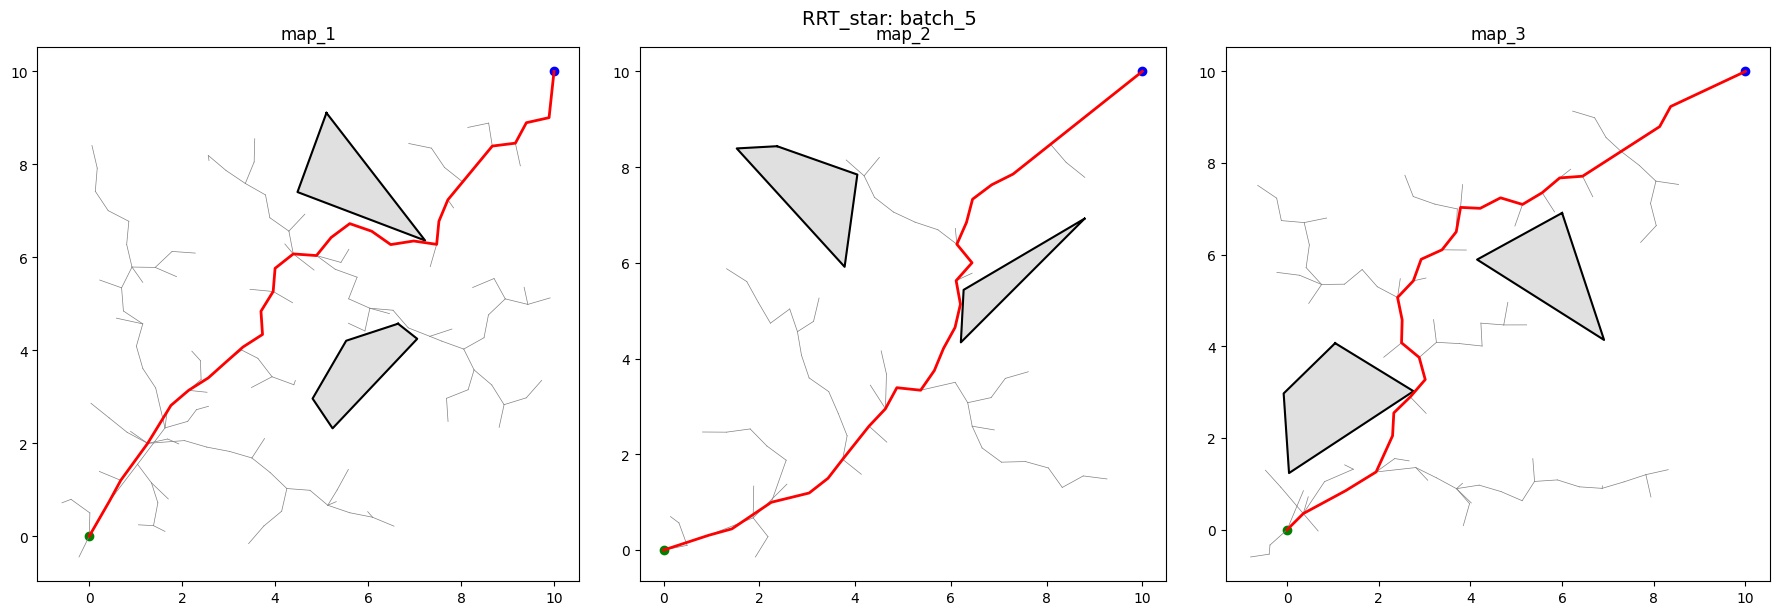

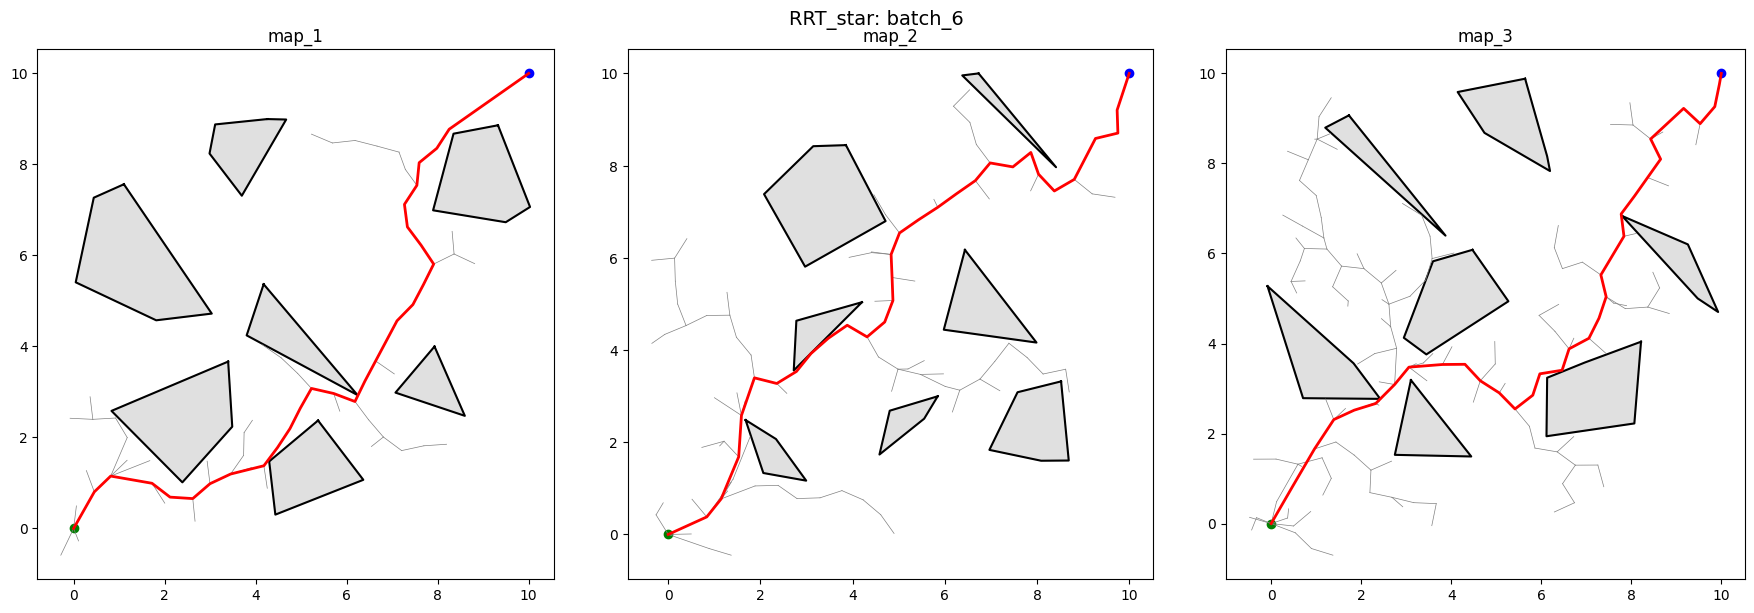

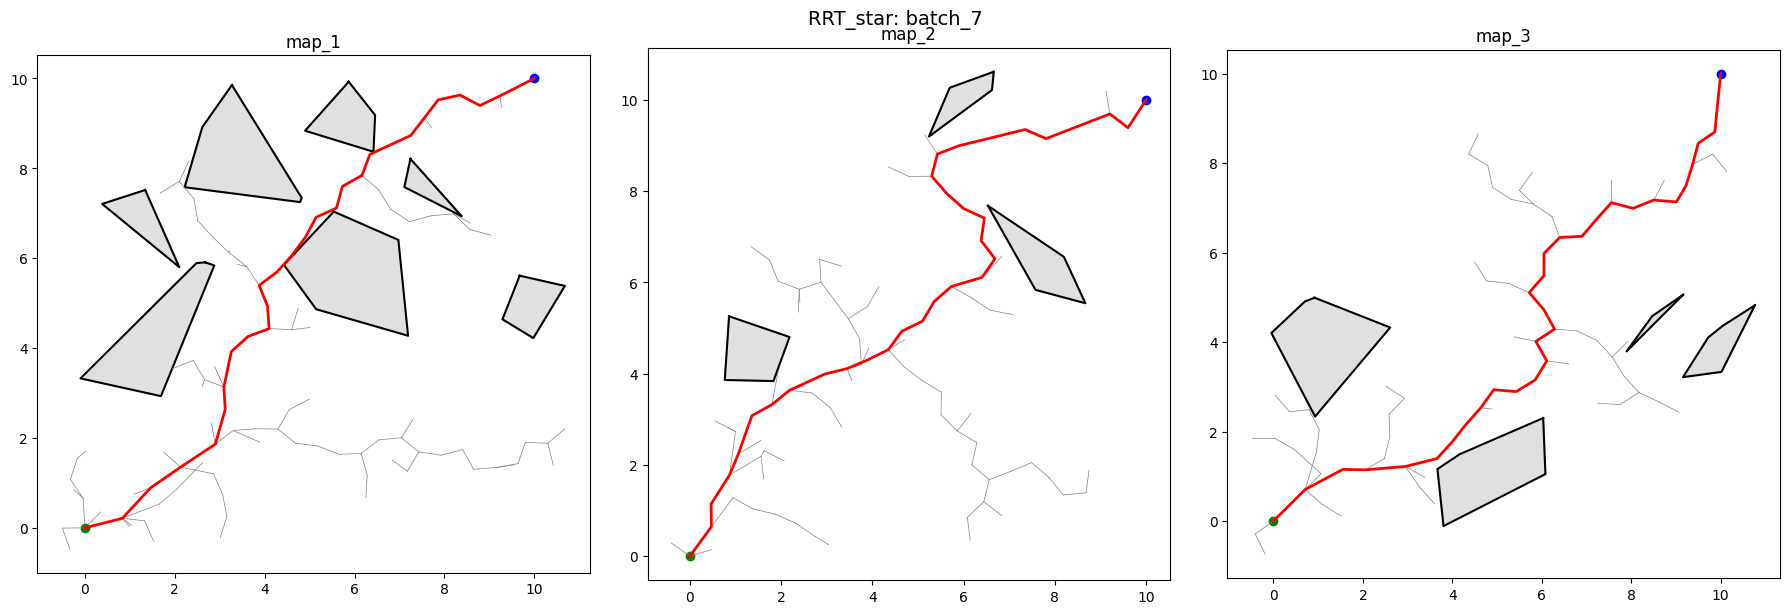

In [6]:
plot_batch_examples_RRT_star(obstacle_batches, start, end, n_examples=N_EXAMPLES, **RRT_KWARGS);

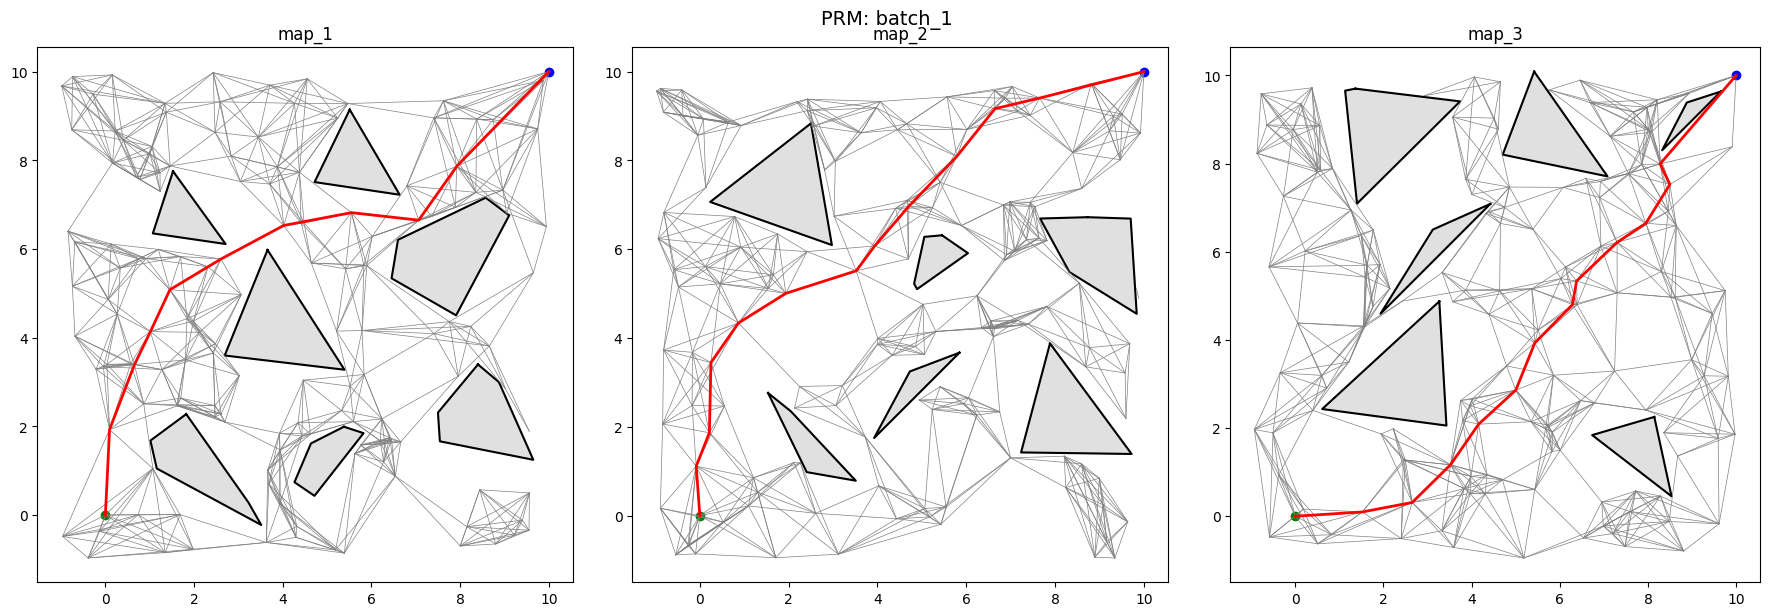

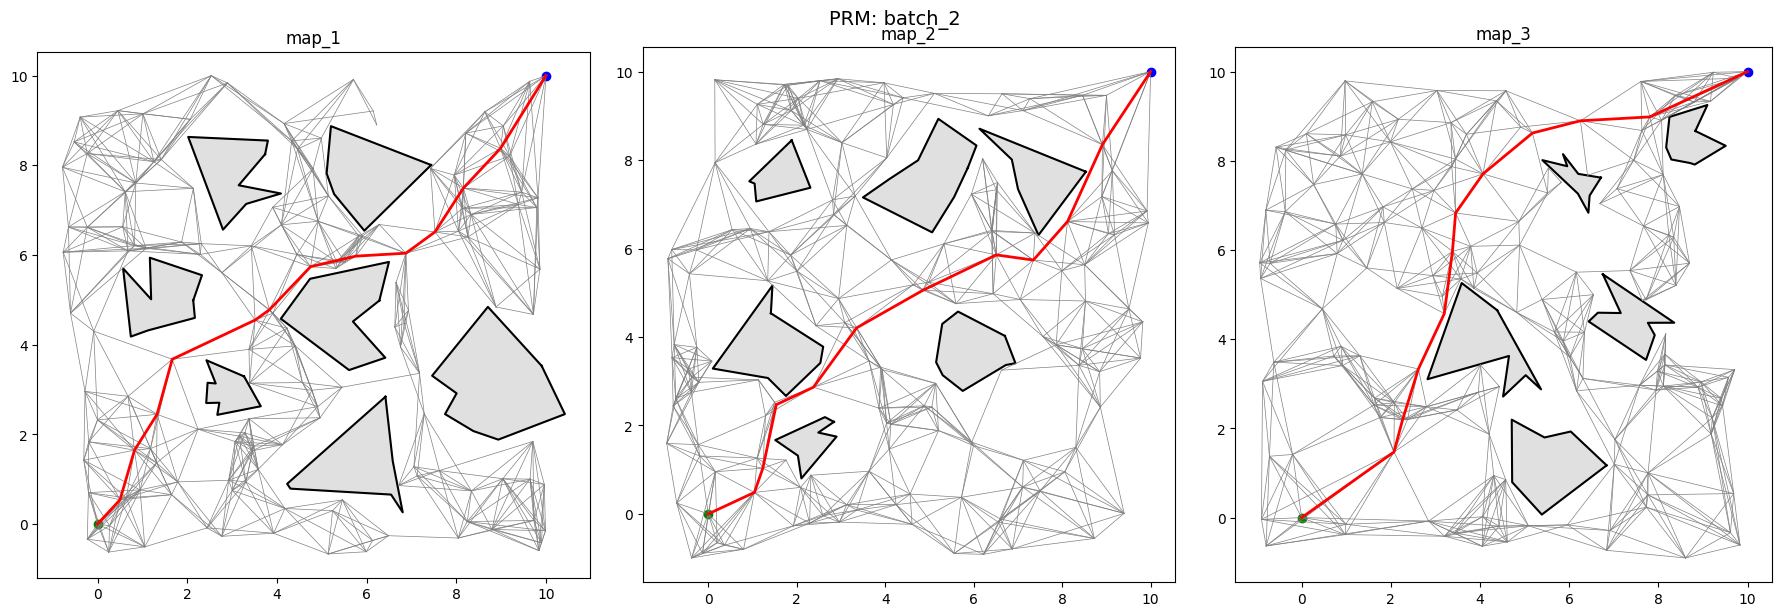

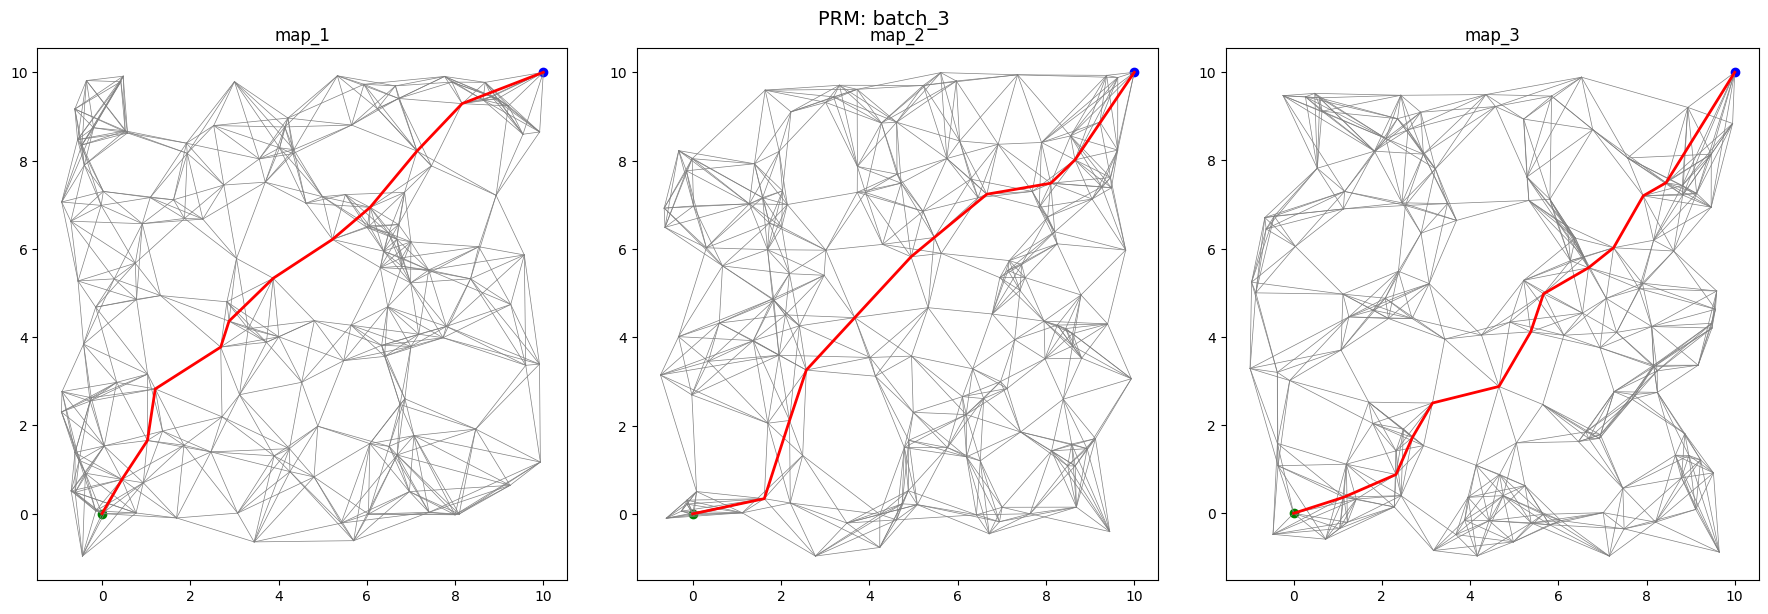

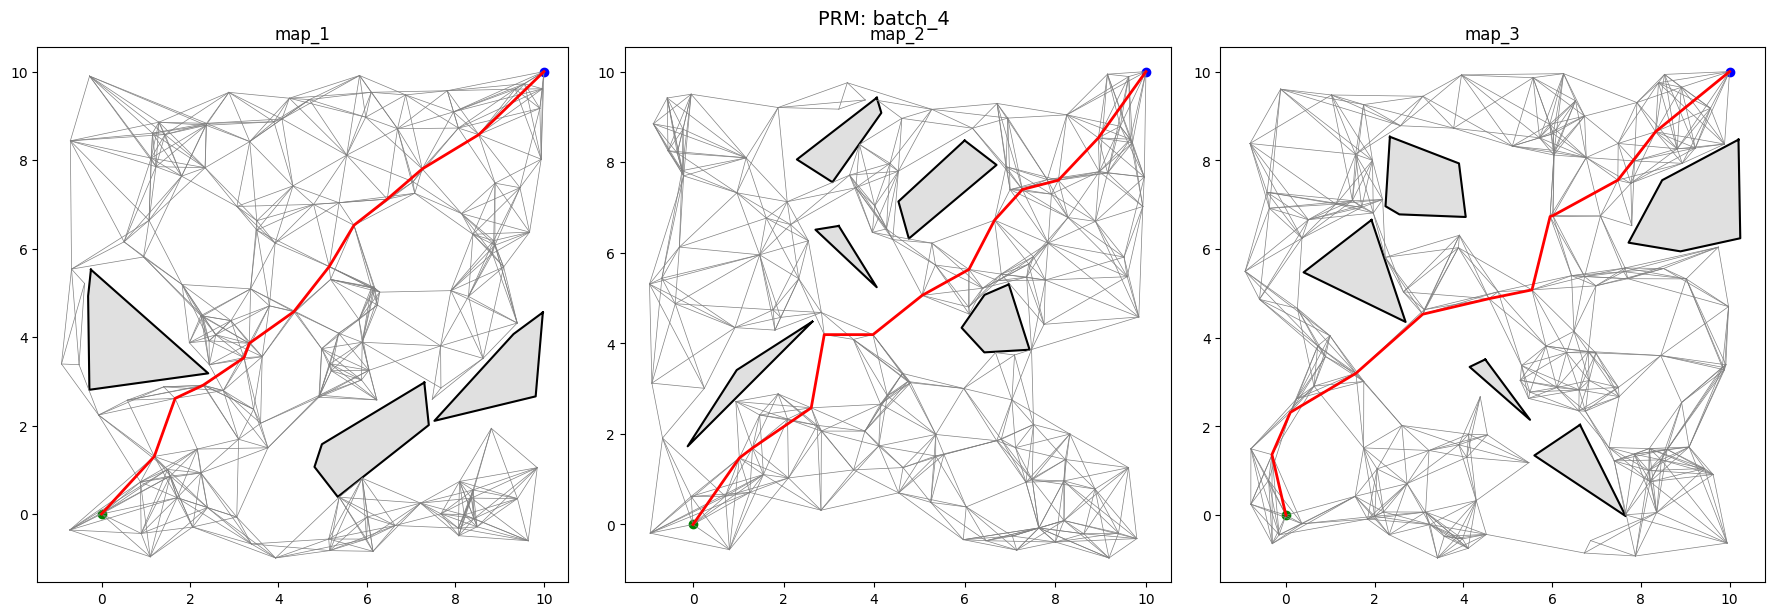

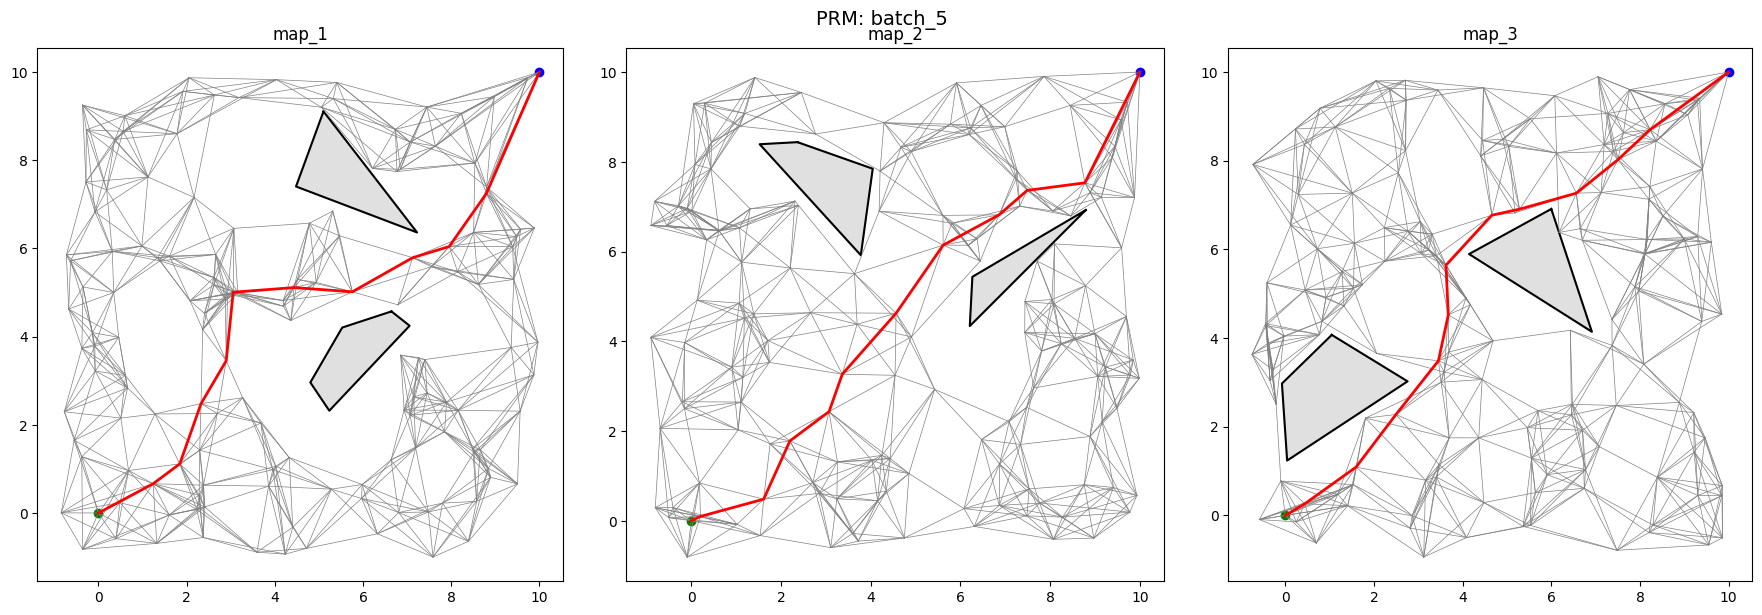

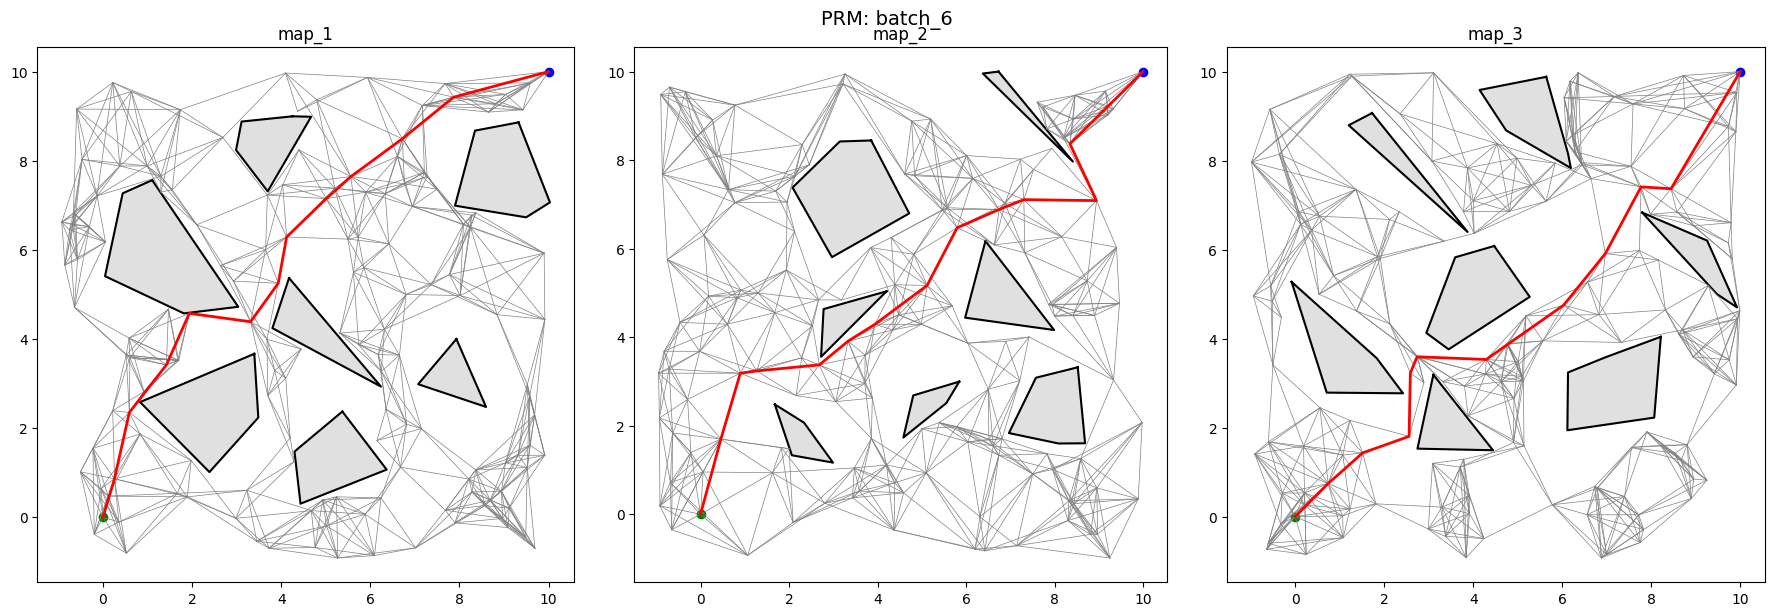

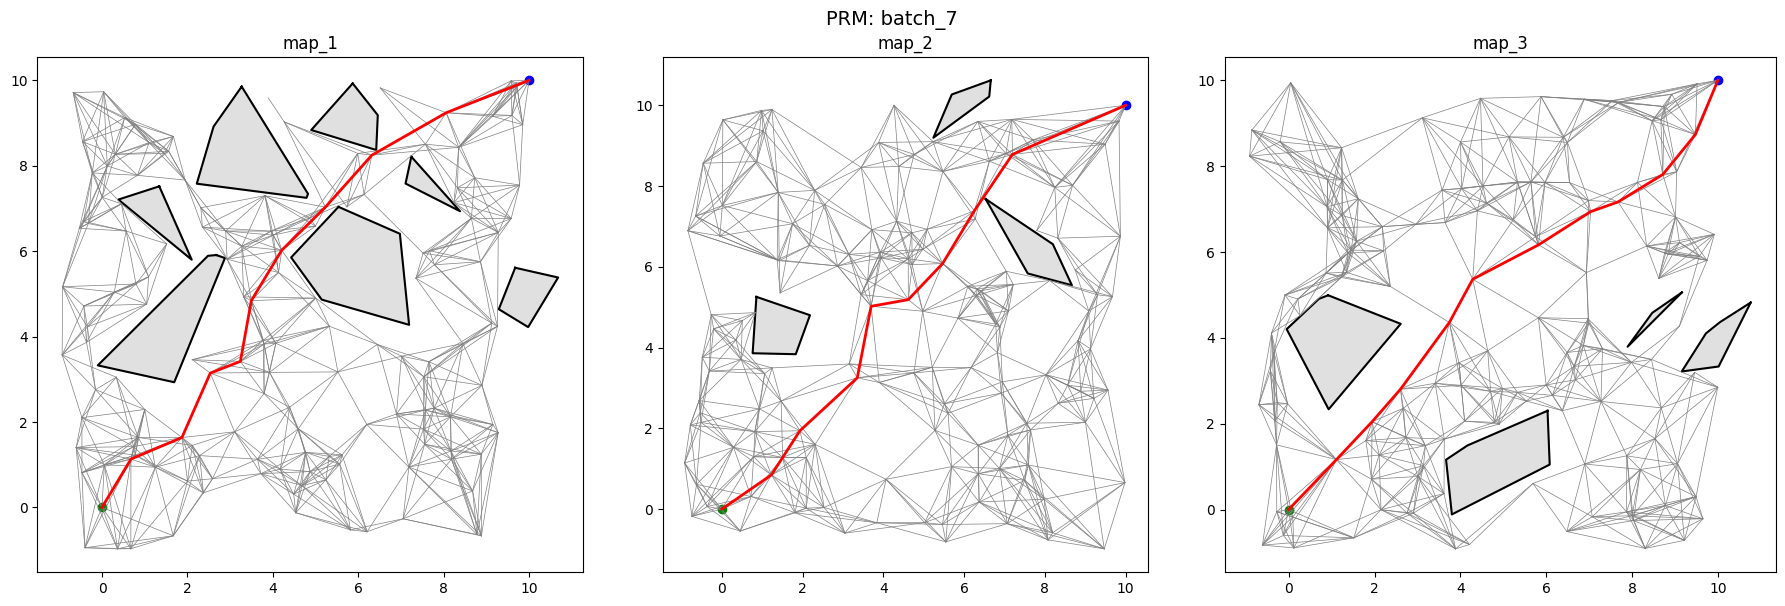

In [7]:
plot_batch_examples_PRM(obstacle_batches, start, end, n_examples=N_EXAMPLES, **PRM_KWARGS);

### Path length per map

In [8]:
path_length_tables = build_path_length_tables(
    obstacle_batches,
    start,
    end,
    rrt_kwargs=RRT_KWARGS,
    prm_kwargs=PRM_KWARGS,
)

show_benchmark_tables("Path length", path_length_tables, summary=False, digits=3)

### Path length: VG

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| map_1 | 14.599 | 14.266 | 14.142 | 14.142 | 14.203 | 14.507 | 14.319 |
| map_2 | 14.324 | 14.281 | 14.142 | 14.142 | 14.142 | 14.261 | 14.254 |
| map_3 | 14.307 | 14.456 | 14.142 | 14.142 | 14.432 | 14.162 | 14.142 |
| map_4 | 14.142 | 14.185 | 14.142 | 14.142 | 14.518 | 14.195 | 14.142 |
| map_5 | 14.142 | 14.248 | 14.142 | 14.142 | 14.142 | 14.897 | 14.509 |
| map_6 | 14.145 | 14.221 | 14.142 | 14.142 | 14.142 | 15.076 | 14.142 |
| map_7 | 14.142 | 14.342 | 14.142 | 14.142 | 14.142 | 14.240 | 14.142 |
| map_8 | 14.390 | 14.509 | 14.142 | 14.142 | 14.316 | 14.189 | 14.409 |
| map_9 | 14.283 | 14.157 | 14.142 | 14.142 | 14.294 | 14.164 | 14.451 |
| map_10 | 14.398 | 14.184 | 14.142 | 14.142 | 14.142 | 14.471 | 14.156 |

### Path length: RRT_star

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| map_1 | 16.575 | 16.726 | 18.358 | 16.506 | 17.039 | 19.790 | 17.431 |
| map_2 | 16.704 | 17.396 | 15.688 | 15.844 | 16.206 | 16.511 | 16.849 |
| map_3 | 16.574 | 17.303 | 15.475 | 17.132 | 19.381 | 18.836 | 16.097 |
| map_4 | 17.039 | 18.400 | 15.385 | 15.736 | 17.941 | 17.444 | 15.582 |
| map_5 | 15.530 | 16.330 | 15.911 | 16.104 | 15.131 | 17.458 | 18.712 |
| map_6 | 16.272 | 15.593 | 15.662 | 15.110 | 15.277 | 18.000 | 16.498 |
| map_7 | 16.189 | 17.148 | 15.858 | 16.859 | 15.446 | 15.681 | 16.297 |
| map_8 | 16.892 | 19.457 | 17.347 | 15.268 | 17.295 | 15.633 | 17.763 |
| map_9 | 19.627 | 16.321 | 15.342 | 15.365 | 17.561 | 16.003 | 17.343 |
| map_10 | 18.496 | 15.860 | 16.240 | 16.610 | 16.609 | 18.111 | 16.262 |

### Path length: PRM

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| map_1 | 15.193 | 14.923 | 14.635 | 14.853 | 14.466 | 16.060 | 16.222 |
| map_2 | 15.434 | 16.061 | 14.584 | 14.508 | 14.863 | 16.000 | 14.985 |
| map_3 | 16.291 | 15.942 | 14.542 | 14.853 | 16.116 | 17.769 | 15.398 |
| map_4 | 14.598 | 15.198 | 14.743 | 16.150 | 16.179 | 15.835 | 15.560 |
| map_5 | 15.246 | 16.255 | 14.925 | 14.746 | 15.149 | NaN | 16.034 |
| map_6 | 15.327 | 15.489 | 14.817 | 14.898 | 15.002 | 17.156 | 14.691 |
| map_7 | 15.613 | 15.153 | 14.802 | 14.780 | 15.784 | 15.460 | 14.689 |
| map_8 | 15.703 | 15.401 | 16.271 | 15.046 | 14.846 | 15.458 | 15.227 |
| map_9 | 17.001 | 15.488 | 14.888 | 14.698 | 15.383 | 14.430 | 14.923 |
| map_10 | 15.613 | 15.144 | 15.280 | 14.710 | 15.770 | 15.134 | 15.423 |

### Mean path length per batch, compared to VG

In [9]:
path_length_comparison = build_path_length_comparison_table(path_length_tables)
display(Markdown(format_benchmark_table("Path length: mean by batch", path_length_comparison, digits=3)))

### Path length: mean by batch

| map | VG | RRT_star | PRM | RRT_star_vs_VG | PRM_vs_VG |
| --- | --- | --- | --- | --- | --- |
| batch_1 | 14.287 | 16.990 | 15.602 | 1.189 | 1.092 |
| batch_2 | 14.285 | 17.053 | 15.505 | 1.194 | 1.085 |
| batch_3 | 14.142 | 16.127 | 14.949 | 1.140 | 1.057 |
| batch_4 | 14.142 | 16.054 | 14.924 | 1.135 | 1.055 |
| batch_5 | 14.247 | 16.789 | 15.356 | 1.178 | 1.078 |
| batch_6 | 14.416 | 17.347 | 15.923 | 1.203 | 1.104 |
| batch_7 | 14.267 | 16.883 | 15.315 | 1.183 | 1.074 |

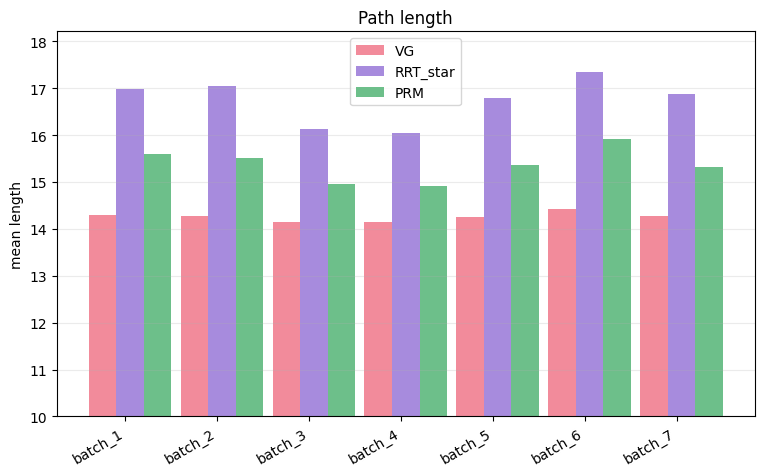

In [10]:
plot_algorithm_batch_means(
    path_length_tables,
    title="Path length",
    ylabel="mean length",
    ymin=10,
);

**Result:** **VG** produced the best path. **PRM** ranked second in path quality, while **RRT\*** showed the worst performance: it found the longest paths among the three.